# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

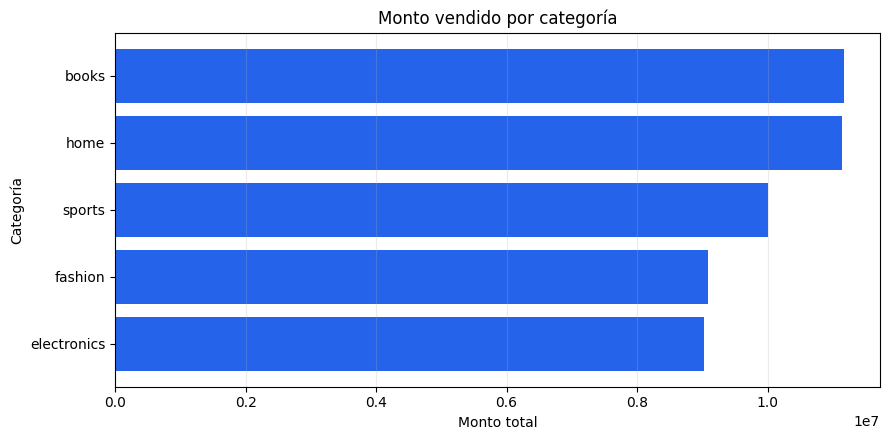

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

sale_date,total_amount,transaction_count,avg_ticket
2026-03-01,7310840.77,7236,1010.342837202875
2026-03-02,7271589.97,7183,1012.333282750940
2026-03-03,7167008.24,7127,1005.613615827136
2026-03-04,7091526.73,7150,991.821920279720
2026-03-05,7010989.71,6958,1007.615652486347
2026-03-06,7198310.64,7129,1009.722350960864
2026-03-07,7089104.28,7165,989.407436147941
2026-03-10,144813.00,200,724.065000000000
2026-03-11,147014.99,201,731.417860696517


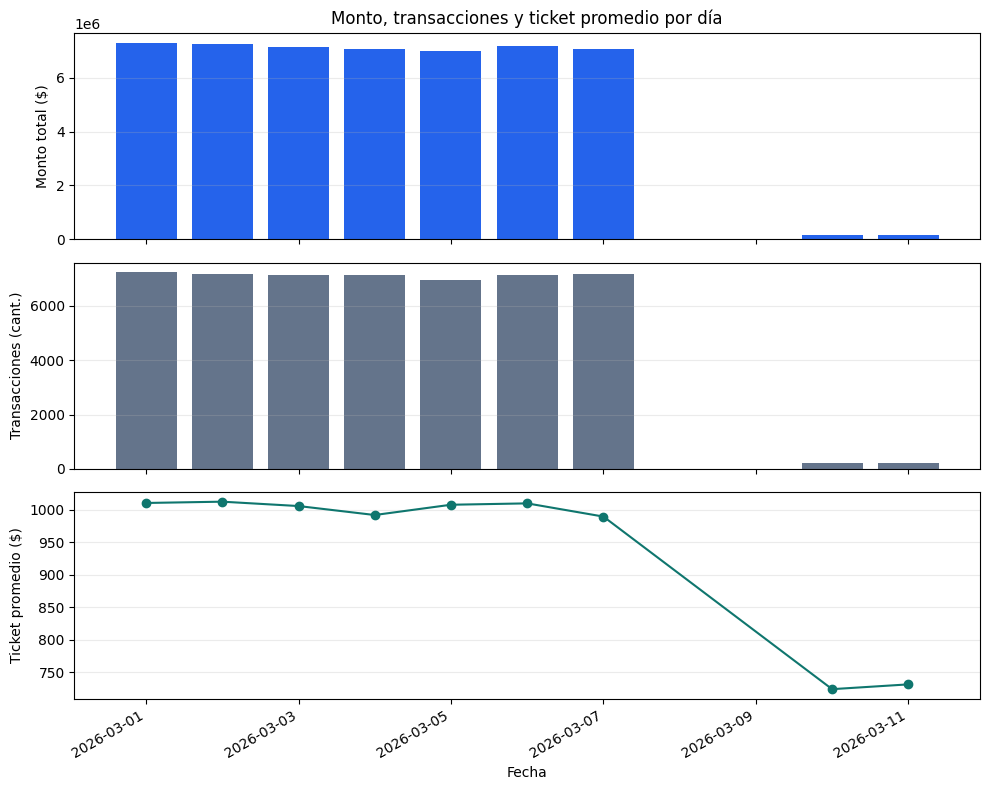

Mayor monto:       2026-03-01 (7,310,840.77)
Más transacciones: 2026-03-01 (7,236)
¿Coinciden? True


In [0]:
# SELECT sale_date, SUM(total_amount), SUM(transaction_count),
#        SUM(total_amount)/SUM(transaction_count) AS avg_ticket
# FROM gold_daily_sales GROUP BY sale_date ORDER BY sale_date

# el equivalente en spark es: 
daily_totals = (spark.table(daily)
    .groupBy("sale_date")
    .agg(F.sum("total_amount").alias("total_amount"),
         F.sum("transaction_count").alias("transaction_count"))
    .withColumn("avg_ticket", F.col("total_amount") / F.col("transaction_count"))
    .orderBy("sale_date"))
display(daily_totals)

# lo paso a pandas y despues grafico
pdf = daily_totals.toPandas()
pdf["total_amount"] = pdf["total_amount"].astype(float)
pdf["avg_ticket"] = pdf["avg_ticket"].astype(float)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax1.bar(pdf["sale_date"], pdf["total_amount"], color="#2563eb")
ax1.set_title("Monto, transacciones y ticket promedio por día")
ax1.set_ylabel("Monto total ($)")
ax1.grid(axis="y", alpha=0.25)

ax2.bar(pdf["sale_date"], pdf["transaction_count"], color="#64748b")
ax2.set_ylabel("Transacciones (cant.)")
ax2.grid(axis="y", alpha=0.25)

ax3.plot(pdf["sale_date"], pdf["avg_ticket"], marker="o", color="#0f766e")
ax3.set_ylabel("Ticket promedio ($)")
ax3.set_xlabel("Fecha")
ax3.grid(axis="y", alpha=0.25)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

max_amount = daily_totals.orderBy(F.desc("total_amount")).first()
max_count = daily_totals.orderBy(F.desc("transaction_count")).first()
print(f"Mayor monto:       {max_amount.sale_date} ({max_amount.total_amount:,.2f})")
print(f"Más transacciones: {max_count.sale_date} ({max_count.transaction_count:,})")
print("¿Coinciden?", max_amount.sale_date == max_count.sale_date)

El día de mayor monto vendido y de mayor cantidad de transacciones es el mismo: 2026-03-01 ($7.310.840 en 7.236 transacciones). Esto implica un ticket promedio estable entre días, porque si el día de mayor monto vendido hubiera tenido menos transacciones que otro, sería porque ese día el ticket subió por algún motivo. Esto lo vemos en el último gráfico de líneas, donde para los primeros 7 días se mantiene alrededor de los $1.000.

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

payment_channel,transaction_count,fraud_transactions,naive_avg_rate,fraud_rate
transfer,16723,2327,0.13906054,0.1391496741015368
wallet,16724,2169,0.12762915,0.1296938531451806
card,16902,2119,0.12473363,0.12536977872441132


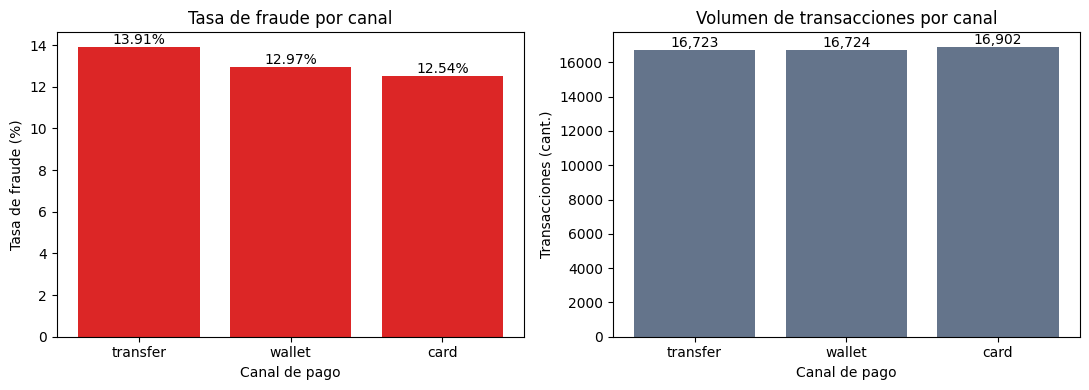

Mayor tasa de fraude: transfer (13.91%, 2,327 fraudes sobre 16,723 transacciones)


In [0]:
# SELECT payment_channel, SUM(transaction_count), SUM(fraud_transactions),
#        SUM(fraud_transactions)/SUM(transaction_count) AS fraud_rate -- correcto
# FROM gold_daily_sales GROUP BY payment_channel

# el equivalente en spark:
channel = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(F.sum("transaction_count").alias("transaction_count"),
         F.sum("fraud_transactions").alias("fraud_transactions"),
         F.avg("fraud_rate").alias("naive_avg_rate"))
    .withColumn("fraud_rate", F.col("fraud_transactions") / F.col("transaction_count"))
    .orderBy(F.desc("fraud_rate")))
display(channel)

# paso a pandas y grafico
pdf = channel.toPandas()
pdf["fraud_rate_pct"] = pdf["fraud_rate"].astype(float) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(pdf["payment_channel"], pdf["fraud_rate_pct"], color="#dc2626")
ax1.set_title("Tasa de fraude por canal")
ax1.set_ylabel("Tasa de fraude (%)")
ax1.set_xlabel("Canal de pago")
for i, v in enumerate(pdf["fraud_rate_pct"]):
    ax1.text(i, v, f"{v:.2f}%", ha="center", va="bottom")

ax2.bar(pdf["payment_channel"], pdf["transaction_count"], color="#64748b")
ax2.set_title("Volumen de transacciones por canal")
ax2.set_ylabel("Transacciones (cant.)")
ax2.set_xlabel("Canal de pago")
for i, v in enumerate(pdf["transaction_count"]):
    ax2.text(i, v, f"{v:,}", ha="center", va="bottom")

fig.tight_layout()
plt.show()

leader = channel.first()
print(f"Mayor tasa de fraude: {leader.payment_channel} ({leader.fraud_rate:.2%}, "
      f"{leader.fraud_transactions:,} fraudes sobre {leader.transaction_count:,} transacciones)")

El canal con mayor tasa de fraude son las transferencias, con un 13,91% sobre el total de transacciones de ese canal, aproximadamente 1 punto por encima de wallet (12,97%) y card (12,54%). La tasa la calculé como fraudes sobre transacciones de cada canal y no promediando `fraud_rate`, porque cada fila de Gold tiene un volumen distinto.

Es útil el gráfico de la derecha sobre el volumen por canal porque nos permite entender si la tasa que informamos es representativa. En este caso vemos que lo es: los 3 canales tienen volúmenes similares y grandes (~16.700 transacciones cada uno). Si, por ejemplo, transfer tuviera solo 100 transacciones, una tasa del 30% sería poco confiable, porque unos pocos casos de más o de menos la moverían mucho; con 16.000 transacciones por canal eso no pasa.

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

country,category,total_amount
AR,books,2267722.26
BR,home,2361959.97
CL,home,2167748.03
MX,books,2235941.63
UY,home,2323924.46


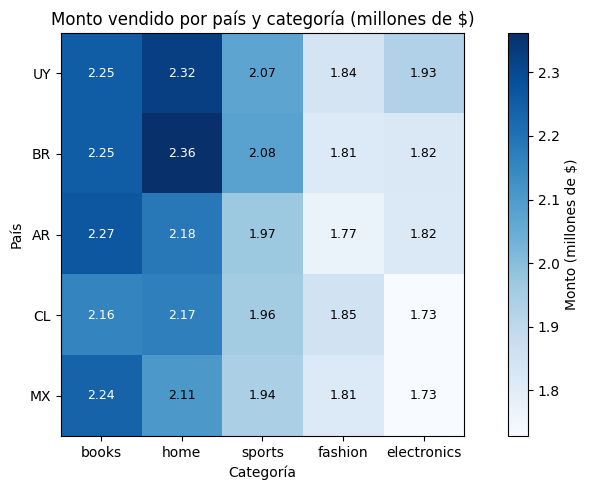

Máximo global: BR × home (2,361,959.97)
Categoría líder por país:
  AR: books (2,267,722.26)
  BR: home (2,361,959.97)
  CL: home (2,167,748.03)
  MX: books (2,235,941.63)
  UY: home (2,323,924.46)


In [0]:
from pyspark.sql.window import Window

# SELECT country, category, SUM(total_amount) 
# FROM gold_daily_sales 
# GROUP BY country, category

#el equivalente en spark es: 
geo = (spark.table(daily)
    .groupBy("country", "category")
    .agg(F.sum("total_amount").alias("total_amount")))

top_global = geo.orderBy(F.desc("total_amount")).first()

# Líder por país: ROW_NUMBER() OVER (PARTITION BY country ORDER BY total_amount DESC) = 1
w = Window.partitionBy("country").orderBy(F.desc("total_amount"))
leaders = (geo.withColumn("rn", F.row_number().over(w))
              .filter("rn = 1").drop("rn").orderBy("country"))
display(leaders)

pdf = geo.toPandas()
pdf["total_amount"] = pdf["total_amount"].astype(float) / 1e6
matrix = pdf.pivot(index="country", columns="category", values="total_amount")
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index,
                    matrix.sum(axis=0).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(matrix.values, cmap="Blues")
ax.set_xticks(range(len(matrix.columns)))
ax.set_xticklabels(matrix.columns)
ax.set_yticks(range(len(matrix.index)))
ax.set_yticklabels(matrix.index)

umbral = matrix.values.min() + 0.6 * (matrix.values.max() - matrix.values.min())
for i in range(len(matrix.index)):
    for j in range(len(matrix.columns)):
        valor = matrix.values[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9,
                color="white" if valor > umbral else "black")

ax.set_title("Monto vendido por país y categoría (millones de $)")
ax.set_xlabel("Categoría")
ax.set_ylabel("País")
fig.colorbar(im, ax=ax, label="Monto (millones de $)")
fig.tight_layout()
plt.show()

print(f"Máximo global: {top_global.country} × {top_global.category} ({float(top_global.total_amount):,.2f})")
print("Categoría líder por país:")
for row in leaders.collect():
    print(f"  {row.country}: {row.category} ({float(row.total_amount):,.2f})")

Elegí un heatmap porque permite comparar una métrica en dos dimensiones simultáneamente: en este caso las categorías y los países, donde la intensidad del azul indica el monto en millones de $ y además cada celda tiene el valor escrito. La combinación de país y categoría que genera el mayor monto es la venta de artículos para el hogar en Brasil ($2,36 M).

No hay una categoría dominante en todos los países: home lidera en Brasil, Chile y Uruguay, y books en Argentina y México (en Chile la diferencia entre ambas es mínima: $2,17 M contra $2,16 M). Lo que sí se mantiene es que home y books son las dos categorías que más monto generan, primeras o segundas en todos los países.

Si bien creo que este dato es valioso, lo complementaría con la cantidad de transacciones por país para entender el market share entre categorías. Con este gráfico vemos que Brasil es el país con más monto en hogar, pero no nos dice si es el mercado donde más gente nos usa para comprar cosas para el hogar o si simplemente más cantidad de transacciones (lo que sería lógico en un mercado más grande como BR)

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

source_batch_id,accepted_transactions,rejected_transactions,total,accept_rate,reject_rate
initial,49948,51,49999,0.998979979599592,0.0010200204004080081
batch_002,200,2,202,0.9900990099009901,0.009900990099009901
batch_003,201,2,203,0.9901477832512315,0.009852216748768473


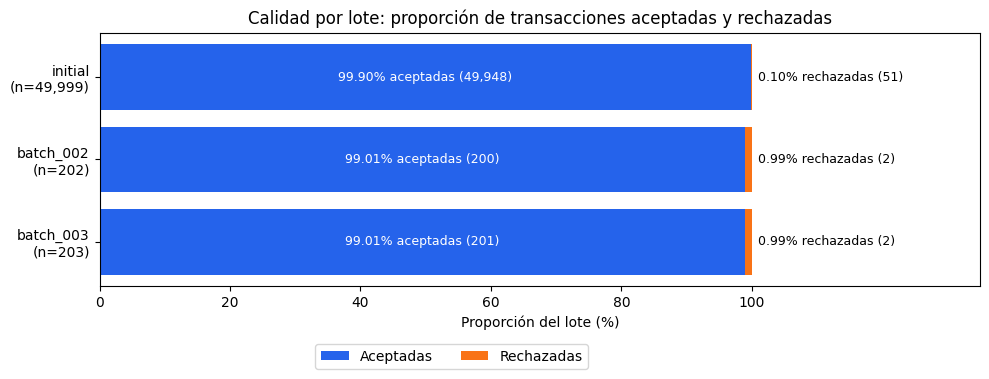

initial: 49,948 aceptadas, 51 rechazadas → 0.10% de rechazo (n=49,999)
batch_002: 200 aceptadas, 2 rechazadas → 0.99% de rechazo (n=202)
batch_003: 201 aceptadas, 2 rechazadas → 0.99% de rechazo (n=203)


In [0]:
# SELECT source_batch_id, accepted_transactions, rejected_transactions,
#        accepted + rejected AS total,
#        accepted / total AS accept_rate, rejected / total AS reject_rate
# FROM gold_batch_summary
# ORDER BY source_batch_id <> 'initial', source_batch_id     -- 'initial' primero

# el equivalente en spark:
batch_q = (spark.table(batch)
    .withColumn("total", F.col("accepted_transactions") + F.col("rejected_transactions"))
    .withColumn("accept_rate", F.col("accepted_transactions") / F.col("total"))
    .withColumn("reject_rate", F.col("rejected_transactions") / F.col("total"))
    .orderBy(F.col("source_batch_id") != "initial", "source_batch_id"))
display(batch_q.select("source_batch_id", "accepted_transactions", "rejected_transactions",
                       "total", "accept_rate", "reject_rate"))

pdf = batch_q.toPandas()
pdf["accept_pct"] = pdf["accept_rate"].astype(float) * 100
pdf["reject_pct"] = pdf["reject_rate"].astype(float) * 100
labels = [f"{b}\n(n={t:,})" for b, t in zip(pdf["source_batch_id"], pdf["total"])]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(labels, pdf["accept_pct"], color="#2563eb", label="Aceptadas")
ax.barh(labels, pdf["reject_pct"], left=pdf["accept_pct"], color="#f97316", label="Rechazadas")

for i, (a, r, na, nr) in enumerate(zip(pdf["accept_pct"], pdf["reject_pct"],
                                       pdf["accepted_transactions"], pdf["rejected_transactions"])):
    ax.text(a / 2, i, f"{a:.2f}% aceptadas ({na:,})", ha="center", va="center", color="white", fontsize=9)
    ax.text(101, i, f"{r:.2f}% rechazadas ({nr:,})", ha="left", va="center", fontsize=9)

ax.set_xlim(0, 135)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Proporción del lote (%)")
ax.set_title("Calidad por lote: proporción de transacciones aceptadas y rechazadas")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2)
fig.tight_layout()
plt.show()

for row in batch_q.collect():
    print(f"{row.source_batch_id}: {row.accepted_transactions:,} aceptadas, "
          f"{row.rejected_transactions:,} rechazadas → {row.reject_rate:.2%} de rechazo (n={row.total:,})")

La calidad de los dos lotes nuevos es la misma: 99,01% de registros aceptados (2 rechazos sobre 202 y 203 transacciones). En proporción, estos lotes tienen una tasa de rechazo mayor que la carga inicial, donde se aceptó el 99,90% (51 rechazos sobre casi 50.000). Es indispensable hacer la evaluación por proporciones y no con valores absolutos, porque eso nos podría llevar a pensar que “solo dos transacciones rechazadas no es grave”, cuando comparado con el estándar inicial la tasa de rechazo es casi 10 veces mayor.

De todas formas hay que tener en cuenta el tamaño de los lotes nuevos. Con ~200 registros, un solo rechazo de más o de menos mueve la tasa medio punto, mientras que en la carga inicial harían falta cientos.

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.